# P2.13 · Training utilities

**ID:** P2.13 · **Target:** 30 min · **Plan week:** 3 · **Part:** P

**The drill.** Write the infrastructure around a training loop that interviewers ask about once the model works.
Guide §P2 "Must include": seeding, device handling, checkpoint save/load (model + optimizer), gradient clipping, AMP,
logging curves. Here also: scheduler + epoch + **all RNG states** in the checkpoint, with a resume test (an
interrupted-then-resumed run must match an uninterrupted run **bit for bit**), clipping by hand vs
`clip_grad_norm_`, fp16 + `GradScaler` vs bf16, and gradient accumulation that matches a big batch exactly.

**Fill in** every `raise NotImplementedError`; run the test cell under each. The training harness (`train`) is
given. It builds every object from scratch on each call, as a restarted job would, and calls your functions.

## Sources
- PyTorch, *Reproducibility* notes (seeding, `use_deterministic_algorithms`, `CUBLAS_WORKSPACE_CONFIG`, cuDNN
  flags, DataLoader `generator` + `worker_init_fn`): https://docs.pytorch.org/docs/stable/notes/randomness.html
- PyTorch recipe, *Saving and loading a general checkpoint*:
  https://docs.pytorch.org/tutorials/recipes/recipes/saving_and_loading_a_general_checkpoint.html
  and `torch.load` (default `weights_only=True` since 2.6): https://docs.pytorch.org/docs/stable/generated/torch.load.html
- PyTorch AMP: package docs https://docs.pytorch.org/docs/stable/amp.html · recipe
  https://docs.pytorch.org/tutorials/recipes/recipes/amp_recipe.html · examples (unscale before clipping, gradient
  accumulation) https://docs.pytorch.org/docs/stable/notes/amp_examples.html
- P. Micikevicius et al., *Mixed Precision Training*, ICLR 2018, arXiv:1710.03740 — https://arxiv.org/abs/1710.03740
  (fp32 master weights, loss scaling, fp16 gradient underflow).
- `torch.nn.utils.clip_grad_norm_` (total norm over all params, `max_norm / (total_norm + 1e-6)` clamped at 1; see
  `torch/nn/utils/clip_grad.py` in torch 2.14.1): https://docs.pytorch.org/docs/stable/generated/torch.nn.utils.clip_grad_norm_.html
- R. Pascanu, T. Mikolov, Y. Bengio, *On the difficulty of training recurrent neural networks*, ICML 2013,
  arXiv:1211.5063 — https://arxiv.org/abs/1211.5063 (gradient-norm clipping).
- Google Deep Learning Tuning Playbook (CC-BY-4.0), commit 7554a51, sections "Gradient clipping" (clip near the 90th
  percentile of logged grad norms) and "Saving checkpoints": https://github.com/google-research/tuning_playbook

In [1]:
import os

os.environ.setdefault("CUBLAS_WORKSPACE_CONFIG", ":4096:8")  # must be set before cuBLAS initializes (Reproducibility notes)

import random
import tempfile
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
from torch.utils.data import DataLoader, TensorDataset

from prep import DATA, Session, check, check_close

s = Session("P2.13", target_min=30)
dev = torch.device("cuda" if torch.cuda.is_available() else "cpu")
mnist = torchvision.datasets.MNIST(DATA, train=True, download=False)
X = mnist.data[:6000].reshape(-1, 784).float() / 255.0
X = (X - X.mean()) / X.std()
Y = mnist.targets[:6000]
train_ds = TensorDataset(X[:5000], Y[:5000])
X_val, Y_val = X[5000:], Y[5000:]
tmpdir = Path(tempfile.mkdtemp())


def make_model():
    return nn.Sequential(nn.Linear(784, 256), nn.ReLU(), nn.Dropout(0.2), nn.Linear(256, 10))

[P2.13] started 16:45; target 30 min


## 1. Seeding and determinism
Seed every generator you use (Python `random`, NumPy, torch CPU, torch CUDA). For bit-identical GPU runs also ask for
deterministic kernels (`torch.use_deterministic_algorithms(True)`, which needs `CUBLAS_WORKSPACE_CONFIG`, set in the
first cell) and turn off cuDNN autotuning. Give the `DataLoader` its **own** `torch.Generator`, so the shuffle order
does not depend on whatever else consumed the global RNG. Pass a `worker_init_fn` when `num_workers > 0`.

In [2]:
def seed_all(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)           # CPU and all CUDA devices
    torch.cuda.manual_seed_all(seed)  # explicit, harmless if no GPU


def set_deterministic():
    torch.use_deterministic_algorithms(True)
    torch.backends.cudnn.benchmark = False
    torch.backends.cudnn.deterministic = True


def seed_worker(worker_id):  # from the Reproducibility notes: each worker reseeds numpy/random from torch's seed
    worker_seed = torch.initial_seed() % 2**32
    np.random.seed(worker_seed)
    random.seed(worker_seed)


def make_loader(ds, batch_size, generator):
    """Shuffled training loader whose order is driven only by `generator`."""
    return DataLoader(ds, batch_size=batch_size, shuffle=True, generator=generator, worker_init_fn=seed_worker,
                      num_workers=0)


set_deterministic()


def short_run(seed, steps=30):
    seed_all(seed)
    model = make_model().to(dev)
    opt = torch.optim.AdamW(model.parameters(), lr=1e-3)
    losses = []
    for i, (xb, yb) in enumerate(make_loader(train_ds, 64, torch.Generator().manual_seed(seed))):
        loss = F.cross_entropy(model(xb.to(dev)), yb.to(dev))
        opt.zero_grad(); loss.backward(); opt.step()
        losses.append(loss.item())
        if i + 1 == steps:
            return losses, [p.detach().clone() for p in model.parameters()]


(l1, p1), (l2, p2), (l3, _) = short_run(0), short_run(0), short_run(1)
check("same seed => identical losses", l1 == l2)
check("same seed => bit-identical parameters", all(torch.equal(a, b) for a, b in zip(p1, p2)))
check("different seed => different run", l1 != l3)
torch.manual_seed(0); first_a = next(iter(make_loader(train_ds, 8, torch.Generator().manual_seed(5))))[1]
torch.manual_seed(999); torch.rand(1000); first_b = next(iter(make_loader(train_ds, 8, torch.Generator().manual_seed(5))))[1]
check("shuffle order depends only on the loader's generator", torch.equal(first_a, first_b))

ok  same seed => identical losses
ok  same seed => bit-identical parameters
ok  different seed => different run
ok  shuffle order depends only on the loader's generator


## 2. Device handling
Move arbitrarily nested batches (dicts, lists, tuples of tensors, with non-tensors left alone) to a device.
`non_blocking=True` lets host-to-device copies overlap compute when the source is in pinned memory.

In [3]:
def to_device(batch, device):
    if torch.is_tensor(batch):
        return batch.to(device, non_blocking=True)
    if isinstance(batch, dict):
        return {k: to_device(v, device) for k, v in batch.items()}
    if isinstance(batch, (list, tuple)):
        return type(batch)(to_device(v, device) for v in batch)
    return batch


nested = {"x": torch.randn(2, 3), "meta": ["id7", torch.arange(3)], "pair": (torch.ones(1), 5)}
moved = to_device(nested, dev)
check("dict tensor moved", moved["x"].device.type == dev.type)
check("nested list/tuple handled, types kept", isinstance(moved["meta"], list) and isinstance(moved["pair"], tuple)
      and moved["meta"][1].device.type == dev.type and moved["pair"][0].device.type == dev.type)
check("non-tensors untouched", moved["meta"][0] == "id7" and moved["pair"][1] == 5)

ok  dict tensor moved
ok  nested list/tuple handled, types kept
ok  non-tensors untouched


## 3. Checkpoint everything, then resume bit-for-bit
A resumable checkpoint holds: model, optimizer (Adam moments + step counts), LR scheduler, epoch, and **every RNG
state** that shapes the rest of the run: torch CPU (noise augmentation below), CUDA (dropout masks), the DataLoader
generator (shuffle order), plus NumPy and Python `random` for completeness. `torch.load` defaults to
`weights_only=True` since PyTorch 2.6, and that refuses NumPy/Python RNG state objects. Load your own trusted file with
`weights_only=False`, or store those states as tensors/lists.

In [4]:
def save_checkpoint(path, model, opt, sched, epoch, loader_gen):
    torch.save({
        "model": model.state_dict(), "opt": opt.state_dict(), "sched": sched.state_dict(), "epoch": epoch,
        "rng": {"torch": torch.get_rng_state(),
                "cuda": torch.cuda.get_rng_state_all() if torch.cuda.is_available() else None,
                "numpy": np.random.get_state(), "python": random.getstate(),
                "loader": loader_gen.get_state()},
    }, path)


def load_checkpoint(path, model, opt, sched, loader_gen):
    """Restore everything in place; return the epoch to start from."""
    ck = torch.load(path, map_location="cpu", weights_only=False)  # our own file: trusted
    model.load_state_dict(ck["model"])
    opt.load_state_dict(ck["opt"])
    sched.load_state_dict(ck["sched"])
    torch.set_rng_state(ck["rng"]["torch"])
    if ck["rng"]["cuda"] is not None:
        torch.cuda.set_rng_state_all(ck["rng"]["cuda"])
    np.random.set_state(ck["rng"]["numpy"])
    random.setstate(ck["rng"]["python"])
    loader_gen.set_state(ck["rng"]["loader"])
    return ck["epoch"] + 1


def train(n_epochs, ckpt=None, resume=False, stop_after=None):
    """Given harness: builds everything fresh (like a new process), optionally resumes, checkpoints every epoch."""
    seed_all(0)
    model = make_model().to(dev)
    opt = torch.optim.AdamW(model.parameters(), lr=2e-3, weight_decay=1e-2)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=n_epochs)
    gen = torch.Generator().manual_seed(0)
    loader = make_loader(train_ds, 64, gen)
    start = load_checkpoint(ckpt, model, opt, sched, gen) if resume else 0
    hist = {"step_loss": [], "val_loss": [], "lr": []}
    for epoch in range(start, n_epochs):
        model.train()
        for xb, yb in loader:
            xb = xb + 0.05 * torch.randn_like(xb)          # augmentation: uses the CPU RNG
            loss = F.cross_entropy(model(xb.to(dev)), yb.to(dev))
            opt.zero_grad(); loss.backward(); opt.step()
            hist["step_loss"].append(loss.item())
        sched.step()
        model.eval()
        with torch.no_grad():
            hist["val_loss"].append(F.cross_entropy(model(X_val.to(dev)), Y_val.to(dev)).item())
        hist["lr"].append(opt.param_groups[0]["lr"])
        if ckpt is not None:
            save_checkpoint(ckpt, model, opt, sched, epoch, gen)
        if stop_after is not None and epoch + 1 == stop_after:
            break                                            # simulated crash / preemption
    return model, opt, hist


t0 = time.time()
m_full, o_full, hist_full = train(4)
ck = tmpdir / "ckpt.pt"
train(4, ckpt=ck, stop_after=2)
torch.manual_seed(12345); torch.randn(777)                   # the "new process" has a different RNG history
m_res, o_res, hist_res = train(4, ckpt=ck, resume=True)
print(f"3 runs in {time.time() - t0:.1f}s; resumed epochs: {len(hist_res['val_loss'])}")
check("resume started at epoch 2", len(hist_res["val_loss"]) == 2)
check("resumed params == uninterrupted params (bit for bit)",
      all(torch.equal(a, b) for a, b in zip(m_full.parameters(), m_res.parameters())))
sa, sb = o_full.state_dict()["state"], o_res.state_dict()["state"]
check("optimizer state identical", all(torch.equal(sa[k]["exp_avg_sq"], sb[k]["exp_avg_sq"]) and
                                       torch.equal(sa[k]["step"], sb[k]["step"]) for k in sa))
check("LR schedule continued", hist_res["lr"] == hist_full["lr"][2:])
check("val curve continued", hist_res["val_loss"] == hist_full["val_loss"][2:])

3 runs in 1.3s; resumed epochs: 2
ok  resume started at epoch 2
ok  resumed params == uninterrupted params (bit for bit)
ok  optimizer state identical
ok  LR schedule continued
ok  val curve continued


## 4. Gradient clipping by global norm, by hand
$\|g\| = \sqrt{\sum_p \|g_p\|_2^2}$ over **all** parameters (not per tensor). If $\|g\| > c$, scale every gradient by
$c/(\|g\|+10^{-6})$. Return the **pre-clip** norm: that is the number you log, and the playbook suggests clipping
near its 90th percentile.

In [5]:
@torch.no_grad()
def clip_grad_norm(params, max_norm):
    grads = [p.grad for p in params if p.grad is not None]
    total = torch.sqrt(sum((g.double() ** 2).sum() for g in grads)).float()
    coef = (max_norm / (total + 1e-6)).clamp(max=1.0)
    for g in grads:
        g.mul_(coef)
    return total


for max_norm in (0.5, 1e3):
    torch.manual_seed(0)
    net_a = make_model(); net_b = make_model(); net_b.load_state_dict(net_a.state_dict())
    for net in (net_a, net_b):
        torch.manual_seed(1)
        F.cross_entropy(net(X[:64] * 3), Y[:64]).backward()
    n_a = clip_grad_norm(list(net_a.parameters()), max_norm)
    n_b = torch.nn.utils.clip_grad_norm_(net_b.parameters(), max_norm)
    check_close(f"max_norm={max_norm}: returned pre-clip norm", n_a, n_b)
    for pa, pb in zip(net_a.parameters(), net_b.parameters()):
        check_close(f"max_norm={max_norm}: clipped grad", pa.grad, pb.grad, atol=1e-7)

ok  max_norm=0.5: returned pre-clip norm
ok  max_norm=0.5: clipped grad
ok  max_norm=0.5: clipped grad
ok  max_norm=0.5: clipped grad
ok  max_norm=0.5: clipped grad
ok  max_norm=1000.0: returned pre-clip norm
ok  max_norm=1000.0: clipped grad
ok  max_norm=1000.0: clipped grad
ok  max_norm=1000.0: clipped grad
ok  max_norm=1000.0: clipped grad


## 5. Mixed precision: fp16 + `GradScaler` vs bf16
Under `torch.autocast`, matmuls run in fp16/bf16 while weights, optimizer state and reductions such as the loss stay
fp32. **fp16** has 5 exponent bits: values below ~6e-8 flush to 0 and above 65504 overflow, so small gradients
underflow. `GradScaler` multiplies the loss by $S$ (initially $2^{16}$), `unscale_` divides the grads back (do this
**before clipping**), `step` skips the update if any grad is inf/NaN, and `update` halves $S$ after a skip and doubles it
after 2000 clean steps. **bf16** keeps fp32's 8 exponent bits (same range, fewer mantissa bits), so gradients do not
underflow and no scaler is needed. Ampere GPUs such as the RTX 3090 support bf16.

In [6]:
print("fp16:", torch.finfo(torch.float16), "\nbf16:", torch.finfo(torch.bfloat16))
print("1e-8 ->", torch.tensor(1e-8).half().item(), "(fp16) vs", torch.tensor(1e-8).bfloat16().item(), "(bf16)")


def train_step_amp(model, opt, scaler, xb, yb, dtype, max_norm=1.0):
    """One AMP step with clipping. scaler=None for bf16. Returns the (unscaled, pre-clip) grad norm."""
    with torch.autocast(device_type=xb.device.type, dtype=dtype):
        loss = F.cross_entropy(model(xb), yb)
    opt.zero_grad(set_to_none=True)
    if scaler is not None:
        scaler.scale(loss).backward()
        scaler.unscale_(opt)
        norm = torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm)
        scaler.step(opt)
        scaler.update()
    else:
        loss.backward()
        norm = torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm)
        opt.step()
    return norm


if dev.type == "cuda":
    xb, yb = X[:256].to(dev), Y[:256].to(dev)
    torch.manual_seed(0); m16 = make_model().to(dev).eval()     # eval: no dropout, so norms are comparable
    m_ref = make_model().to(dev).eval(); m_ref.load_state_dict(m16.state_dict())
    F.cross_entropy(m_ref(xb), yb).backward()
    ref_norm = torch.sqrt(sum((p.grad ** 2).sum() for p in m_ref.parameters()))
    opt16 = torch.optim.SGD(m16.parameters(), lr=0.1)
    scaler = torch.amp.GradScaler("cuda")
    before = [p.detach().clone() for p in m16.parameters()]
    n16 = train_step_amp(m16, opt16, scaler, xb, yb, torch.float16)
    check("fp16: returned norm is unscaled (unscale_ before clip)", abs(n16.item() / ref_norm.item() - 1) < 0.05,
          f"{n16.item():.4g} vs fp32 {ref_norm.item():.4g}")
    check("fp16: params updated", any(not torch.equal(a, b) for a, b in zip(before, m16.parameters())))
    check("fp16: params stay fp32", all(p.dtype == torch.float32 for p in m16.parameters()))
    scale0 = scaler.get_scale()
    before = [p.detach().clone() for p in m16.parameters()]
    bad = xb.clone(); bad[0, 0] = float("inf")
    train_step_amp(m16, opt16, scaler, bad, yb, torch.float16)
    check("fp16: inf grads => step skipped", all(torch.equal(a, b) for a, b in zip(before, m16.parameters())))
    check("fp16: inf grads => scale halved", scaler.get_scale() == scale0 / 2, f"{scale0} -> {scaler.get_scale()}")

    finals = {}
    for name, dtype in (("fp32", None), ("fp16", torch.float16), ("bf16", torch.bfloat16)):
        torch.manual_seed(0); m = make_model().to(dev)
        o = torch.optim.AdamW(m.parameters(), lr=1e-3)
        sc = torch.amp.GradScaler("cuda") if dtype == torch.float16 else None
        g = torch.Generator().manual_seed(0)
        for ep in range(2):
            for xb_, yb_ in make_loader(train_ds, 128, g):
                xb_, yb_ = xb_.to(dev), yb_.to(dev)
                if dtype is None:
                    o.zero_grad(); F.cross_entropy(m(xb_), yb_).backward(); o.step()
                else:
                    train_step_amp(m, o, sc, xb_, yb_, dtype, max_norm=1e9)
        m.eval()
        with torch.no_grad():
            finals[name] = F.cross_entropy(m(X_val.to(dev)), Y_val.to(dev)).item()
    print("val loss after 2 epochs:", {k: round(v, 4) for k, v in finals.items()})
    check("fp16 and bf16 training match fp32 closely", all(abs(finals[k] - finals["fp32"]) < 0.05 for k in ("fp16", "bf16")))
else:
    print("no GPU: AMP section skipped")

fp16: finfo(resolution=0.001, min=-65504, max=65504, eps=0.000976562, smallest_normal=6.10352e-05, tiny=6.10352e-05, dtype=float16) 
bf16: finfo(resolution=0.01, min=-3.38953e+38, max=3.38953e+38, eps=0.0078125, smallest_normal=1.17549e-38, tiny=1.17549e-38, dtype=bfloat16)
1e-8 -> 0.0 (fp16) vs 1.0011717677116394e-08 (bf16)


ok  fp16: returned norm is unscaled (unscale_ before clip)
ok  fp16: params updated
ok  fp16: params stay fp32
ok  fp16: inf grads => step skipped
ok  fp16: inf grads => scale halved


val loss after 2 epochs: {'fp32': 0.341, 'fp16': 0.3294, 'bf16': 0.3294}
ok  fp16 and bf16 training match fp32 closely


## 6. Gradient accumulation == big batch
For a mean loss over $N$ examples split into micro-batches of sizes $n_j$, the big-batch gradient is
$\sum_j \frac{n_j}{N}\nabla \bar\ell_j$. So scale each micro-batch loss by $n_j/N$ (which is $1/k$ only when all chunks are
equal) and call `backward` k times before one `step`. Exact for models without batch-coupled layers (BatchNorm breaks it).

In [7]:
def accumulate_grads(model, x, y, micro_bs):
    """Leave in .grad exactly the gradient of the mean CE over the full (x, y)."""
    model.zero_grad(set_to_none=True)
    N = len(x)
    for xc, yc in zip(x.split(micro_bs), y.split(micro_bs)):
        (F.cross_entropy(model(xc), yc) * (len(xc) / N)).backward()


torch.manual_seed(0)
net = nn.Sequential(nn.Linear(784, 64), nn.Tanh(), nn.Linear(64, 10)).double()
xa, ya = X[:100].double(), Y[:100]
big = torch.autograd.grad(F.cross_entropy(net(xa), ya), list(net.parameters()))
accumulate_grads(net, xa, ya, micro_bs=32)
accumulate_grads(net, xa, ya, micro_bs=32)                     # twice: stale grads from the first call must not leak in
for (n, p), g in zip(net.named_parameters(), big):
    check_close(f"accumulated grad {n} == big-batch grad (chunks 32, 32, 32, 4)", p.grad, g, atol=1e-10)

ok  accumulated grad 0.weight == big-batch grad (chunks 32, 32, 32, 4)
ok  accumulated grad 0.bias == big-batch grad (chunks 32, 32, 32, 4)
ok  accumulated grad 2.weight == big-batch grad (chunks 32, 32, 32, 4)
ok  accumulated grad 2.bias == big-batch grad (chunks 32, 32, 32, 4)


## 7. Logging curves
Per-step losses are noisy. Plot them raw *and* smoothed with a **debiased** EMA,
$m_t = \beta m_{t-1} + (1-\beta)x_t$, $\hat m_t = m_t/(1-\beta^t)$ (without the correction the curve starts near 0).
Plot validation per epoch on the same step axis. In real runs, write the same scalars to a CSV/JSONL file or a
tracker as well, so the curves survive the notebook.

ok  debiased EMA
ok  EMA of a constant is the constant (from step 1)


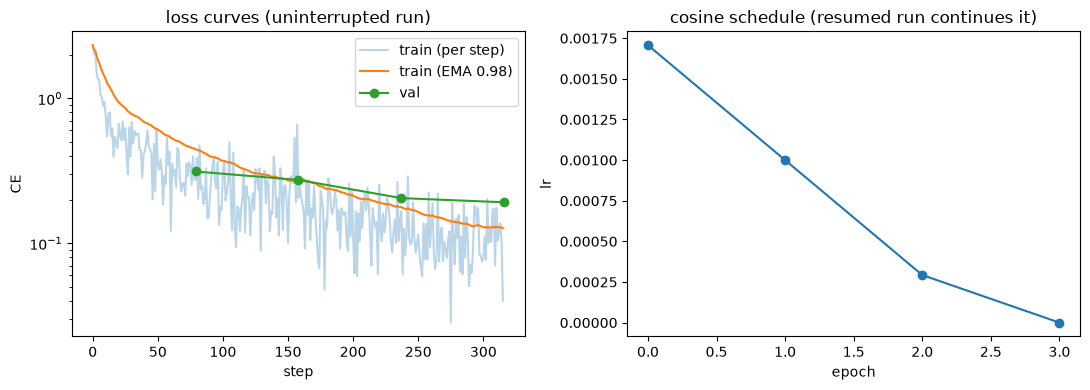

In [8]:
def ema(xs, beta=0.98):
    out, m = [], 0.0
    for t, x in enumerate(xs, 1):
        m = beta * m + (1 - beta) * x
        out.append(m / (1 - beta**t))
    return out


xs = np.random.default_rng(0).normal(size=50).tolist()
brute = [sum(0.9 ** (t - i) * 0.1 * xs[i] for i in range(t + 1)) / (1 - 0.9 ** (t + 1)) for t in range(50)]
check_close("debiased EMA", ema(xs, 0.9), brute)
check_close("EMA of a constant is the constant (from step 1)", ema([3.0] * 5, 0.98), [3.0] * 5)

steps_per_epoch = len(hist_full["step_loss"]) // len(hist_full["val_loss"])
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(hist_full["step_loss"], alpha=0.3, label="train (per step)")
ax[0].plot(ema(hist_full["step_loss"]), label="train (EMA 0.98)")
ax[0].plot([(e + 1) * steps_per_epoch for e in range(len(hist_full["val_loss"]))], hist_full["val_loss"], "o-", label="val")
ax[0].set(xlabel="step", ylabel="CE", yscale="log", title="loss curves (uninterrupted run)")
ax[0].legend()
ax[1].plot(hist_full["lr"], "o-")
ax[1].set(xlabel="epoch", ylabel="lr", title="cosine schedule (resumed run continues it)")
plt.tight_layout(); plt.show()

## Say it out loud
1. List everything that must go into a checkpoint for an exact resume. Which item do people forget most, and what symptom does it cause?
2. Seeding is not enough for bit-identical GPU runs. Why? What does `use_deterministic_algorithms` cost?
3. Why must you `unscale_` before clipping with a `GradScaler`? What happens on a step with inf gradients?
4. Why does bf16 not need loss scaling? When would you still pick fp16?
5. When is gradient accumulation exactly equivalent to a bigger batch, and when is it not?
6. Clipping by global norm vs by value vs per-parameter: what does each preserve? How do you choose the threshold?
7. `torch.load` raised `UnpicklingError` on your checkpoint. Why, and what are the safe fixes?

<details><summary>Model answers</summary>

1. Model `state_dict`, optimizer `state_dict` (moments and step counts), scheduler, epoch/step, the DataLoader
   sampler/generator state, RNG states (torch CPU, every CUDA device, NumPy, Python), the GradScaler state if you use AMP,
   and the config. Most often forgotten: the optimizer state (the Adam moments restart at 0, so the bias correction restarts with them and you get a
   loss spike after resume) and the data order (epochs re-see the same shuffle, so the resumed run silently differs).
2. Many GPU kernels are nondeterministic: atomics in scatter/index_add backward, cuBLAS split-K reductions, and cuDNN
   autotuning picks different algorithms run to run. Floating-point addition is not associative, so a different order
   gives different bits. `use_deterministic_algorithms(True)` forces deterministic implementations, or raises if none
   exists. They can be slower, and cuBLAS needs `CUBLAS_WORKSPACE_CONFIG` (PyTorch Reproducibility notes). Determinism holds only
   for the same hardware, software versions and batch shapes.
3. The grads in `.grad` are multiplied by the scale S (e.g. 65536). Clipping them to norm 1 would clip far too hard,
   and the threshold would change meaning every time S changes. `unscale_` divides by S in place and records inf/NaN. Then `scaler.step`
   skips `opt.step()` if any were found, and `scaler.update()` multiplies S by 0.5. Clean steps double S every 2000 steps
   (defaults). Loss scaling and the fp32 master copy are from Micikevicius et al. 2018 (arXiv:1710.03740).
4. bf16 has an 8-bit exponent like fp32 (max ≈ 3.4e38, smallest normal ≈ 1.2e-38), so the small gradient values that
   underflow in fp16 (normal min 6.1e-5, subnormal min ≈ 6e-8) are representable. It pays for this with 7 mantissa bits vs fp16's 10.
   Pick fp16 on hardware without bf16 (pre-Ampere NVIDIA, e.g. V100/T4), or when the extra mantissa precision matters (some inference).
5. It is exact when the loss is a mean over i.i.d. examples, you weight each micro-batch by its share of examples (or tokens),
   and no layer couples examples within a batch. BatchNorm statistics differ (micro-batch stats), and so do batch-level losses (in-batch
   negatives in contrastive learning: fewer negatives per micro-batch). Results also differ by floating-point summation order and by
   the dropout masks drawn. Optimizer and schedule steps count *updates*, so step-based schedules must be in optimizer steps.
6. Global-norm clipping rescales the whole gradient vector, so it keeps the update direction and caps only its length. Clipping by value
   changes the direction. Per-parameter norms change relative magnitudes across layers. The threshold: log the unclipped norm and start near
   its 90th percentile (Tuning Playbook). If more than ~50% of steps clip, you are really lowering the LR.
7. Since PyTorch 2.6 `torch.load` defaults to `weights_only=True`, which only unpickles tensors, primitive containers and
   allow-listed types. NumPy RNG state (a tuple holding an ndarray) and arbitrary objects are rejected. Fixes: `weights_only=False`
   for files you created yourself (unpickling can run arbitrary code, so never do this for downloaded files), store RNG
   states as tensors/lists, or allow-list specific types with `torch.serialization.add_safe_globals`.
</details>

In [9]:
s.finish(lookups=0, score=None, notes="")

[P2.13] done in 0.1 min (within target 30 min)


0.06728699604670206